In [316]:
#importing the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [317]:
#loading the dataset and preprocessing
billing_df= pd.read_csv("d:\\project\\4. Basic stats - 2\\Billing_Data.csv")
patient_df= pd.read_csv("d:\\project\\4. Basic stats - 2\\Patient_Data.csv")

In [318]:

billing_df.head()

,PatientID,InsuranceCovered,FinalAmount
0,101,2000,3000
1,102,1500,3500
2,103,2500,5000
3,104,3000,3200
4,105,1000,4000


In [319]:

billing_df.head()
billing_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   PatientID         5 non-null      int64
 1   InsuranceCovered  5 non-null      int64
 2   FinalAmount       5 non-null      int64
dtypes: int64(3)
memory usage: 252.0 bytes


In [320]:
patient_df.head()

,PatientID,Name,Department,Doctor,BillAmount,ReceptionistID,CheckInTime
0,101,Alice,Cardiology,Dr. Smith,5000.0,1,2023-01-10 09:00
1,102,Bob,Neurology,Dr. John,NaN,2,2023-01-11 10:30
2,103,Charlie,Orthopedics,Dr. Lee,7500.0,1,2023-01-12 11:00
3,104,David,Cardiology,Dr. Smith,6200.0,3,2023-01-13 12:00
4,105,Eva,Dermatology,Dr. Rose,NaN,2,2023-01-14 08:45


In [321]:
patient_df.head()
patient_df.info()

patient_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   PatientID       6 non-null      int64  
 1   Name            6 non-null      str    
 2   Department      6 non-null      str    
 3   Doctor          6 non-null      str    
 4   BillAmount      4 non-null      float64
 5   ReceptionistID  6 non-null      int64  
 6   CheckInTime     6 non-null      str    
dtypes: float64(1), int64(2), str(4)
memory usage: 468.0 bytes


PatientID         0
Name              0
Department        0
Doctor            0
BillAmount        2
ReceptionistID    0
CheckInTime       0
dtype: int64

In [322]:
#dropping the unnecessary columns
patient_df = patient_df.drop(columns=["ReceptionistID", "CheckInTime"])
patient_df.head()

,PatientID,Name,Department,Doctor,BillAmount
0,101,Alice,Cardiology,Dr. Smith,5000.0
1,102,Bob,Neurology,Dr. John,NaN
2,103,Charlie,Orthopedics,Dr. Lee,7500.0
3,104,David,Cardiology,Dr. Smith,6200.0
4,105,Eva,Dermatology,Dr. Rose,NaN


In [ ]:
#groupi ng the data set to find the null values
department_df= patient_df.groupby("Department", as_index=False)["BillAmount"].sum()
department_df 

,Department,BillAmount
0,Cardiology,16200.0
1,Dermatology,0.0
2,Neurology,0.0
3,Orthopedics,7500.0


In [324]:
patient_df["BillAmount"]=patient_df["BillAmount"].fillna(bill)

In [325]:
#dropping the duplicate values
patient_df=patient_df.drop_duplicates(subset="PatientID", keep="first")

In [326]:
patient_df

,PatientID,Name,Department,Doctor,BillAmount
0,101,Alice,Cardiology,Dr. Smith,5000.000000
1,102,Bob,Neurology,Dr. John,6233.333333
2,103,Charlie,Orthopedics,Dr. Lee,7500.000000
3,104,David,Cardiology,Dr. Smith,6200.000000
4,105,Eva,Dermatology,Dr. Rose,6233.333333


In [327]:
#creating the new dataset
new_df=pd.DataFrame({
    "PatientID":["106","107","108","109"],
    "Name":["Michael","Priya","Jeremy","Rachel"],
    "Department":["Cardiology", "Orthopedics","Cardiology","Neurology"],
    "Doctor":["Dr. Smith","Dr. Lee","Dr. Smith","Dr. John"],
    "BillAmount":["4500","8000","5500","7000"]
})

In [328]:
#merging the new data with the existing dataset
patient_df=pd.concat(
    [patient_df, new_df],
    axis=0,
    ignore_index= True
)

In [329]:
patient_df.tail()

,PatientID,Name,Department,Doctor,BillAmount
4,105,Eva,Dermatology,Dr. Rose,6233.333333
5,106,Michael,Cardiology,Dr. Smith,4500
6,107,Priya,Orthopedics,Dr. Lee,8000
7,108,Jeremy,Cardiology,Dr. Smith,5500
8,109,Rachel,Neurology,Dr. John,7000


In [330]:
#checking the duplicate values
patient_df["PatientID"].duplicated().sum()

np.int64(0)

In [331]:
patient_df.head()

,PatientID,Name,Department,Doctor,BillAmount
0,101,Alice,Cardiology,Dr. Smith,5000.0
1,102,Bob,Neurology,Dr. John,6233.333333
2,103,Charlie,Orthopedics,Dr. Lee,7500.0
3,104,David,Cardiology,Dr. Smith,6200.0
4,105,Eva,Dermatology,Dr. Rose,6233.333333


In [332]:
#merging the both data set
patient_df=pd.merge(
    patient_df,
    billing_df[["PatientID","InsuranceCovered","FinalAmount"]],
    on="PatientID",
    how="left"
)
patient_df

,PatientID,Name,Department,Doctor,BillAmount,InsuranceCovered,FinalAmount
0,101,Alice,Cardiology,Dr. Smith,5000.0,2000.0,3000.0
1,102,Bob,Neurology,Dr. John,6233.333333,1500.0,3500.0
2,103,Charlie,Orthopedics,Dr. Lee,7500.0,2500.0,5000.0
3,104,David,Cardiology,Dr. Smith,6200.0,3000.0,3200.0
4,105,Eva,Dermatology,Dr. Rose,6233.333333,1000.0,4000.0
5,106,Michael,Cardiology,Dr. Smith,4500,NaN,NaN
6,107,Priya,Orthopedics,Dr. Lee,8000,NaN,NaN
7,108,Jeremy,Cardiology,Dr. Smith,5500,NaN,NaN
8,109,Rachel,Neurology,Dr. John,7000,NaN,NaN


In [333]:
#checking for null values
print(patient_df[["InsuranceCovered", "FinalAmount"]].isnull().sum())

InsuranceCovered    4
FinalAmount         4
dtype: int64


In [334]:
#finding mean to fit in the null values
print("Mean InsuranceCovered:",patient_df["InsuranceCovered"].mean())
print("Mean FinalAmount:", patient_df["FinalAmount"].mean())

Mean InsuranceCovered: 2000.0
Mean FinalAmount: 3740.0


In [335]:
#putting the null values in the data set
patient_df["InsuranceCovered"] = patient_df["InsuranceCovered"].fillna(
    patient_df["InsuranceCovered"].mean()
)
patient_df["FinalAmount"]= patient_df["FinalAmount"].fillna(
    patient_df["FinalAmount"].mean()
)


In [336]:
#Final data set
patient_df

,PatientID,Name,Department,Doctor,BillAmount,InsuranceCovered,FinalAmount
0,101,Alice,Cardiology,Dr. Smith,5000.0,2000.0,3000.0
1,102,Bob,Neurology,Dr. John,6233.333333,1500.0,3500.0
2,103,Charlie,Orthopedics,Dr. Lee,7500.0,2500.0,5000.0
3,104,David,Cardiology,Dr. Smith,6200.0,3000.0,3200.0
4,105,Eva,Dermatology,Dr. Rose,6233.333333,1000.0,4000.0
5,106,Michael,Cardiology,Dr. Smith,4500,2000.0,3740.0
6,107,Priya,Orthopedics,Dr. Lee,8000,2000.0,3740.0
7,108,Jeremy,Cardiology,Dr. Smith,5500,2000.0,3740.0
8,109,Rachel,Neurology,Dr. John,7000,2000.0,3740.0


In [337]:
patient_df["BillAmount"].dtype
patient_df["BillAmount"]=pd.to_numeric(
    patient_df["BillAmount"], errors="coerce"
)

In [345]:
#calculate the total revenue earned by each doctor
doctor_revenue=(
    patient_df.groupby("Doctor", as_index= False)["BillAmount"]
    .sum()
    
)
doctor_revenue

,Doctor,BillAmount
0,Dr. John,13233.333333
1,Dr. Lee,15500.000000
2,Dr. Rose,6233.333333
3,Dr. Smith,21200.000000


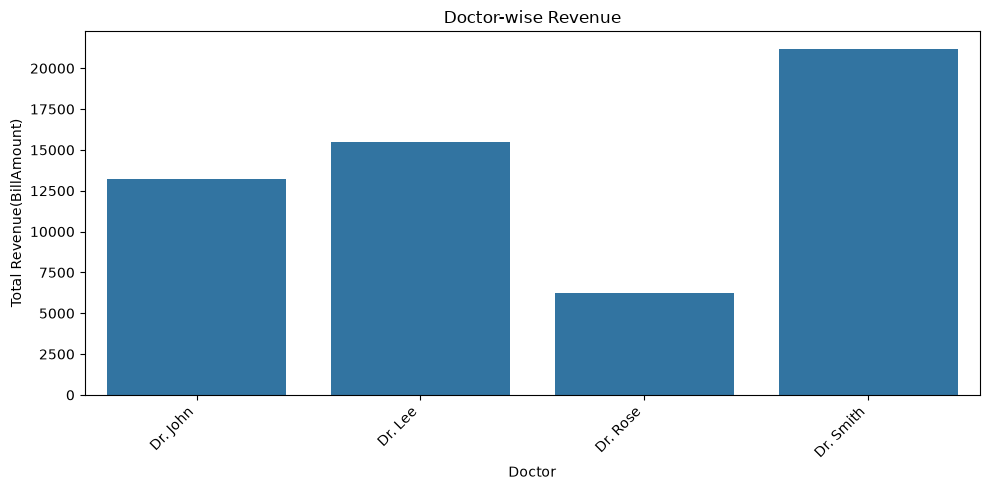

In [ ]:
#creating a bar chart
plt.figure(figsize=(10,5))

sns.barplot(
    data=doctor_revenue,
    x="Doctor",
    y="BillAmount"
)
plt.title("Doctor-wise Revenue")
plt.xlabel("Doctor")
plt.ylabel("Total Revenue(BillAmount)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [344]:
#calculating the insurance covered for each doctor
insurance_by_doctor=(
    patient_df.groupby("Doctor", as_index= False)["InsuranceCovered"]
    .sum()
)
insurance_by_doctor

,Doctor,InsuranceCovered
0,Dr. John,3500.0
1,Dr. Lee,4500.0
2,Dr. Rose,1000.0
3,Dr. Smith,9000.0


<function matplotlib.pyplot.show(close=None, block=None)>

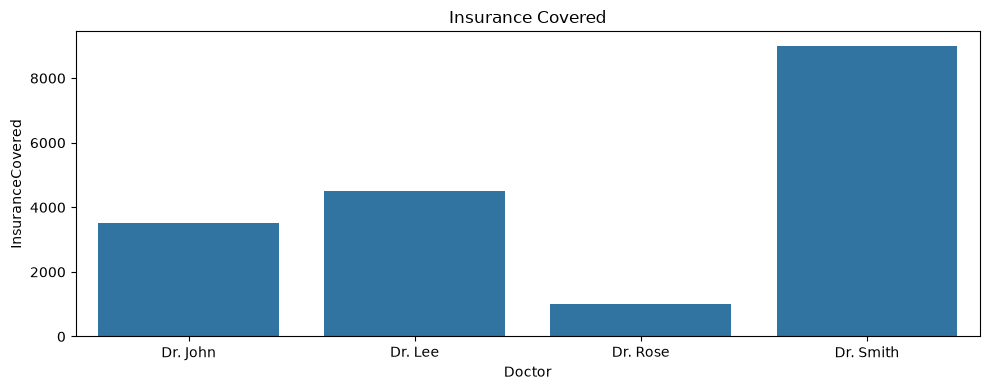

In [ ]:
#creating a graph
plt.figure(figsize=(10,4))

sns.barplot(
    data=insurance_by_doctor,
    x="Doctor",
    y="InsuranceCovered"
)
plt.title("Insurance Covered")
plt.xlabel("Doctor")
plt.ylabel("InsuranceCovered")
plt.xticks(ha='center')
plt.tight_layout()

plt.show

In [366]:
department_summary = (
    patient_df.groupby("Department")
    .agg(
        Total_Revenue=("BillAmount", "sum"),
        Average_Bill=("BillAmount", "mean"),
        Patient_Records=("PatientID", "count")
    )
    .sort_values(by="Total_Revenue", ascending=False)
)

print(department_summary)

             Total_Revenue  Average_Bill  Patient_Records
Department                                               
Cardiology    21200.000000   5300.000000                4
Orthopedics   15500.000000   7750.000000                2
Neurology     13233.333333   6616.666667                2
Dermatology    6233.333333   6233.333333                1


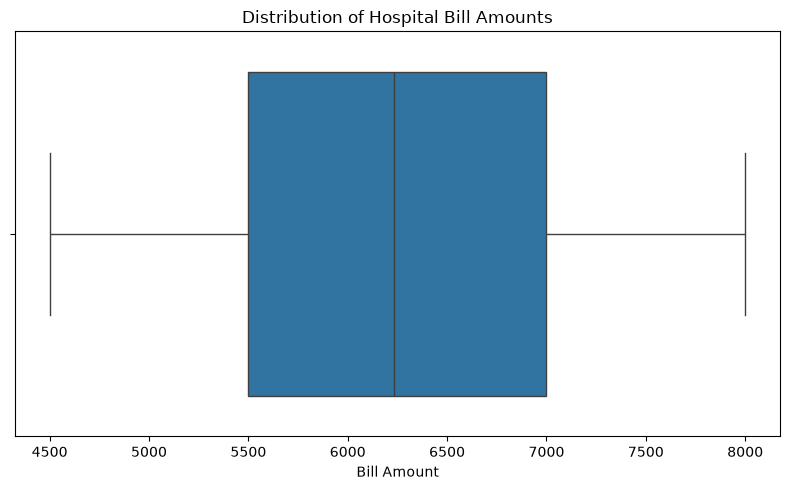

In [368]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=patient_df, x="BillAmount")

plt.title("Distribution of Hospital Bill Amounts")
plt.xlabel("Bill Amount")
plt.tight_layout()
plt.show()

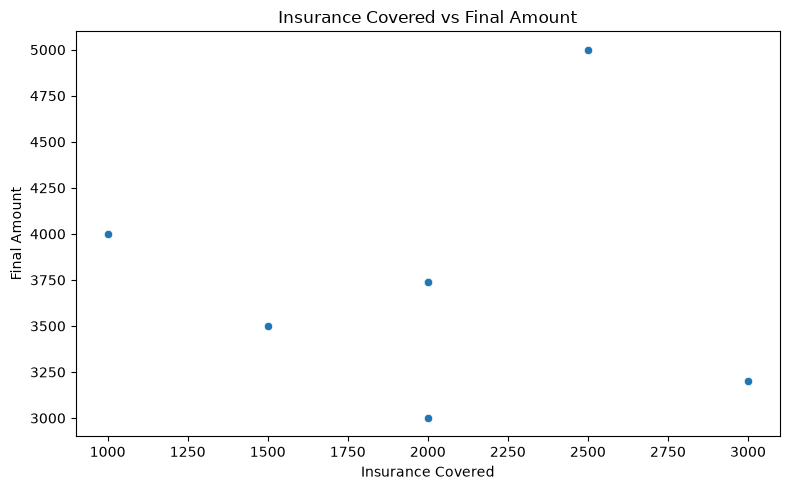

In [372]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=patient_df,
    x="InsuranceCovered",
    y="FinalAmount"
)

plt.title("Insurance Covered vs Final Amount")
plt.xlabel("Insurance Covered")
plt.ylabel("Final Amount")
plt.tight_layout()
plt.show()